In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
tf.keras.utils.set_random_seed(42)

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [3]:
X_train = train.drop('label', axis=1)
y_train = train['label']

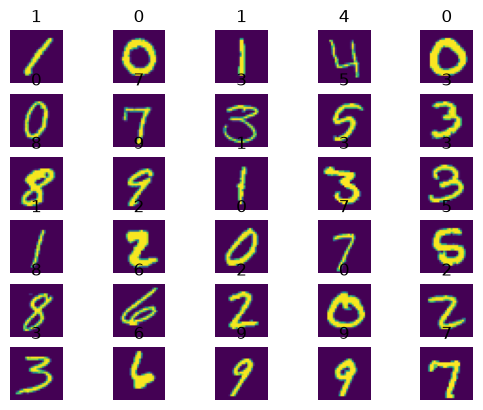

In [4]:
plt.figsize = (10, 10)
for i in range(30) :
    plt.subplot(6, 5, i+1)
    # plt.imshow(X_train = train.drop('label', axis=1)
    plt.imshow(X_train.iloc[i].values.reshape(28, 28), cmap='gray')
    plt.imshow(X_train.iloc[i].values.reshape(28, 28))
    # plt.imshow(X_train.iloc[i].values.reshape(28, 28), cmap=plt.cm.binary)
    plt.title(y_train.iloc[i])
    plt.axis('off')

In [5]:
X_train = X_train.values.reshape(-1, 28, 28, 1)
x_train = X_train / 255.0
y_train = tf.keras.utils.to_categorical(y_train, num_classes=10)

In [6]:
y_train

array([[0., 1., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.]], shape=(42000, 10))

In [7]:
model = models.Sequential()
model.add(layers.Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(16, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(10, activation='softmax'))


c:\Users\besha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [9]:
model.fit(x_train, y_train, epochs=10, validation_split=0.2, batch_size=128)

Epoch 1/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.8322 - loss: 0.5327 - val_accuracy: 0.9538 - val_loss: 0.1528
Epoch 2/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9618 - loss: 0.1272 - val_accuracy: 0.9668 - val_loss: 0.1036
Epoch 3/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9727 - loss: 0.0901 - val_accuracy: 0.9702 - val_loss: 0.0905
Epoch 4/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9774 - loss: 0.0724 - val_accuracy: 0.9726 - val_loss: 0.0845
Epoch 5/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9812 - loss: 0.0620 - val_accuracy: 0.9737 - val_loss: 0.0830
Epoch 6/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9838 - loss: 0.0547 - val_accuracy: 0.9736 - val_loss: 0.0809
Epoch 7/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9857 - loss: 0.0484 - val_accuracy: 0.9750 - val_loss: 0.0764
Epoch 8/10
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9875 - loss: 0.0432 - val_acc

In [10]:
x_test = test.values.reshape(-1, 28, 28, 1)
x_test = x_test / 255.0
y_pred = model.predict(x_test)

875/875 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


In [11]:
y_pred

array([[7.4152757e-07, 4.0595438e-13, 9.9999416e-01, ..., 8.2948638e-08,
        1.4317942e-08, 1.2799158e-10],
       [1.0000000e+00, 2.7336828e-15, 4.6523563e-09, ..., 8.1169521e-10,
        1.0122072e-10, 2.0031809e-08],
       [5.6704636e-07, 5.1919060e-09, 1.7827275e-05, ..., 6.2601648e-06,
        8.1949343e-05, 9.9981421e-01],
       ...,
       [3.3189835e-13, 3.9582714e-14, 1.7709156e-12, ..., 4.3352006e-12,
        8.2747714e-10, 4.5428510e-09],
       [3.6084103e-08, 3.7614789e-10, 2.1787476e-09, ..., 3.4446657e-07,
        1.5146090e-07, 9.9995768e-01],
       [4.8751886e-08, 1.3603682e-12, 9.9999917e-01, ..., 2.7583642e-08,
        7.9367504e-07, 3.2400134e-09]], shape=(28000, 10), dtype=float32)

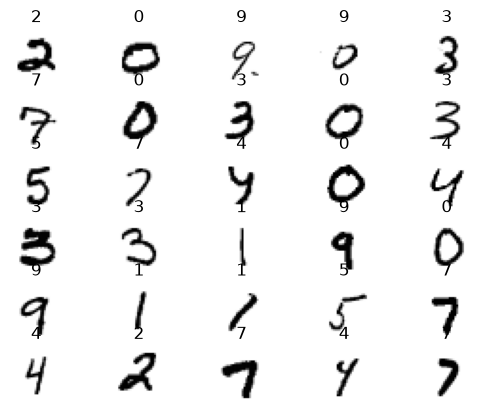

In [12]:
plt.figsize = (10, 10)
for i in range(30) :
    plt.subplot(6, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap=plt.cm.binary)
    plt.title(np.argmax(y_pred[i]))
    plt.axis('off')

In [13]:
submission = pd.DataFrame({'ImageId': list(range(1, len(y_pred) + 1)), 'Label': np.argmax(y_pred, axis=1)})
submission.to_csv('submission.csv', index=False)